# 03 · Step 3: Quick uplift model and first Qini chart (gate K4)
**Question:** can we predict who buys *because of* the message, not just who buys?

**Plan**
1. Split the 200,039 experiment customers 70% train / 30% test (same message and buy mix in both).
2. Train two standard uplift methods with gradient-boosted trees:
   - **T-learner:** model A = buying among messaged, model B = buying among not messaged; uplift = A − B.
   - **Class transformation:** relabel (messaged & bought) or (not messaged & not bought) = 1; one model; uplift = 2 × score − 1.
3. Score the locked 30% test half; draw the **Qini chart** and the **decile table**.
4. See which customers have high uplift and which measures drive it.
5. **K4 verdict:** go or stop.

## Cell 0 · Setup and data
Loads the profiles built in Step 2 (experiment customers only) and turns gender into three 0/1 columns.

In [ ]:
    import pandas as pd, numpy as np, duckdb, time
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 40)

FEAT = Path('..') / 'data_x5' / 'features'
df = duckdb.sql(f"SELECT * FROM '{(FEAT / 'customer_profiles.parquet').as_posix()}' WHERE in_experiment = 1").df()
df = pd.concat([df, pd.get_dummies(df.gender, prefix='gender').astype(int)], axis=1)

DROP = {'client_id', 'gender', 'treatment_flg', 'target', 'in_experiment'}
X_COLS = [c for c in df.columns if c not in DROP]
df[X_COLS] = df[X_COLS].astype(float)
df['treatment_flg'] = df.treatment_flg.astype(int); df['target'] = df.target.astype(int)
print(f'{len(df):,} customers | {len(X_COLS)} input measures | treated share {df.treatment_flg.mean():.3f} | buy rate {df.target.mean():.3f}')

200,039 customers | 69 input measures | treated share 0.500 | buy rate 0.620


## Cell 1 · Fair split
70% to learn from, 30% locked away. `stratify` keeps the same share of (messaged, bought) combinations in both halves; `random_state=42` makes it repeatable.

In [2]:
strata = df.treatment_flg * 2 + df.target
train, test = train_test_split(df, test_size=0.30, stratify=strata, random_state=42)
for name, d in [('train', train), ('test', test)]:
    print(f'{name:5s} {len(d):7,} rows | treated {d.treatment_flg.mean():.3f} | buy rate {d.target.mean():.3f} | '
          f'lift {(d[d.treatment_flg==1].target.mean() - d[d.treatment_flg==0].target.mean())*100:+.2f} pts')

train 140,027 rows | treated 0.500 | buy rate 0.620 | lift +3.32 pts
test   60,012 rows | treated 0.500 | buy rate 0.620 | lift +3.32 pts


## Cell 2 · Train the two uplift models
**Gradient-boosted trees** (scikit-learn `HistGradientBoostingClassifier`): many small trees, each correcting the last; handles blanks natively. Early stopping on an internal 10% slice prevents over-fitting.

In [3]:
def gbm():
    return HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, max_leaf_nodes=31, min_samples_leaf=200,
                                          l2_regularization=1.0, early_stopping=True, validation_fraction=0.1,
                                          n_iter_no_change=30, random_state=42)
t0 = time.time()
tr_t, tr_c = train[train.treatment_flg == 1], train[train.treatment_flg == 0]

# T-learner: two buy models
mA = gbm().fit(tr_t[X_COLS], tr_t.target)       # buying when messaged
mB = gbm().fit(tr_c[X_COLS], tr_c.target)       # buying when not messaged
# Class transformation: one model on the relabelled target
z = (train.treatment_flg * train.target + (1 - train.treatment_flg) * (1 - train.target)).astype(int)
mZ = gbm().fit(train[X_COLS], z)

test = test.copy()
test['uplift_tlearner'] = mA.predict_proba(test[X_COLS])[:, 1] - mB.predict_proba(test[X_COLS])[:, 1]
test['uplift_classtrans'] = 2 * mZ.predict_proba(test[X_COLS])[:, 1] - 1
print(f'trained in {time.time()-t0:.0f}s | trees used: A={mA.n_iter_}, B={mB.n_iter_}, Z={mZ.n_iter_}')
display(test[['uplift_tlearner', 'uplift_classtrans']].describe(percentiles=[.1, .5, .9]).T.round(4))
print('agreement between the two models (rank correlation):',
      round(test.uplift_tlearner.rank().corr(test.uplift_classtrans.rank()), 3))

trained in 11s | trees used: A=154, B=151, Z=65


,count,mean,std,min,10%,50%,90%,max
uplift_tlearner,60012.0,0.0346,0.0577,-0.2463,-0.0252,0.0264,0.1042,0.5926
uplift_classtrans,60012.0,0.0334,0.0425,-0.1608,-0.0064,0.0268,0.0776,0.5488


agreement between the two models (rank correlation): 0.426


## Cell 3 · Qini curve, uplift at top 30%, decile table
**Qini curve:** sort test customers by predicted uplift. For each top slice, extra buyers = buyers among messaged − buyers among not messaged × (messaged count ÷ not-messaged count). Random targeting is the straight line from 0 to the total.

**Qini area:** area between the model's curve and the random line. Positive = targeting beats random. A 95% range comes from 200 bootstrap resamples of the test half.

In [4]:
def qini_curve(y, t, u):
    o = np.argsort(-u, kind='stable'); y, t = y[o], t[o]
    nt, nc = np.cumsum(t), np.cumsum(1 - t)
    yt, yc = np.cumsum(y * t), np.cumsum(y * (1 - t))
    q = yt - yc * np.divide(nt, nc, out=np.zeros_like(nt, dtype=float), where=nc > 0)
    x = np.arange(1, len(y) + 1) / len(y)
    return np.r_[0, x], np.r_[0, q]

def qini_area(y, t, u):
    x, q = qini_curve(y, t, u)
    return np.trapezoid(q, x) - q[-1] / 2          # area above the random line

def uplift_at(y, t, u, k=0.3):
    top = np.argsort(-u, kind='stable')[:int(len(u) * k)]
    return y[top][t[top] == 1].mean() - y[top][t[top] == 0].mean()

y, t = test.target.values, test.treatment_flg.values
rng = np.random.default_rng(42)
boot_idx = [rng.integers(0, len(y), len(y)) for _ in range(200)]
res = {}
for m in ['uplift_tlearner', 'uplift_classtrans']:
    u = test[m].values
    boots = [qini_area(y[i], t[i], u[i]) for i in boot_idx]
    res[m] = {'qini_area': qini_area(y, t, u), 'qini_low95': np.percentile(boots, 2.5), 'qini_high95': np.percentile(boots, 97.5),
              'uplift_top30_pts': uplift_at(y, t, u, 0.3) * 100, 'uplift_top10_pts': uplift_at(y, t, u, 0.1) * 100}
res = pd.DataFrame(res).T
res['avg_lift_pts'] = (y[t == 1].mean() - y[t == 0].mean()) * 100
display(res.round(3))
BEST = res.qini_area.idxmax(); print('better model:', BEST)

try:   # independent cross-check with the scikit-uplift library, if installed
    from sklift.metrics import qini_auc_score, uplift_at_k
    for m in res.index:
        print(m, '| sklift qini_auc', round(qini_auc_score(y, test[m].values, t), 4),
              '| sklift uplift@30%', round(uplift_at_k(y, test[m].values, t, strategy='overall', k=0.3) * 100, 2), 'pts')
except ImportError:
    print('(scikit-uplift not installed: cross-check skipped; pip install scikit-uplift to enable)')

,qini_area,qini_low95,qini_high95,uplift_top30_pts,uplift_top10_pts,avg_lift_pts
uplift_tlearner,103.901,37.275,168.310,5.167,6.161,3.321
uplift_classtrans,102.883,44.205,175.791,5.613,8.690,3.321


better model: uplift_tlearner
uplift_tlearner | sklift qini_auc 0.0081 | sklift uplift@30% 5.17 pts
uplift_classtrans | sklift qini_auc 0.008 | sklift uplift@30% 5.61 pts


## Cell 4 · Charts: Qini curves and lift by decile
**Left:** the higher a curve sits above the dashed random line, the better the targeting.
**Right:** real lift (buy rate with message − without) in each tenth of customers, ranked by predicted uplift. A good model gives tall bars on the left, short on the right.

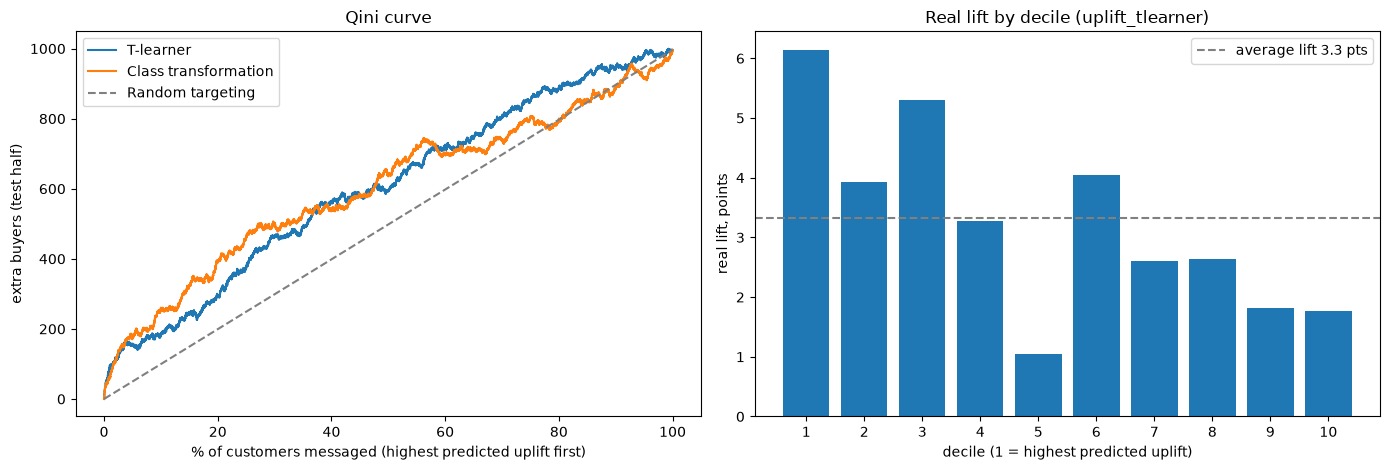

,customers,buy_rate_msg,buy_rate_no_msg,predicted_uplift,real_lift_pts
decile,,,,,
1,6002.0,0.552,0.490,0.152,6.145
2,6001.0,0.564,0.525,0.087,3.921
3,6001.0,0.597,0.544,0.063,5.308
4,6001.0,0.607,0.574,0.046,3.274
5,6001.0,0.645,0.634,0.032,1.041
6,6001.0,0.698,0.657,0.021,4.047
7,6001.0,0.732,0.706,0.011,2.600
8,6001.0,0.723,0.697,0.000,2.641
9,6001.0,0.645,0.627,-0.015,1.821


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for m, lab in [('uplift_tlearner', 'T-learner'), ('uplift_classtrans', 'Class transformation')]:
    x, q = qini_curve(y, t, test[m].values); ax[0].plot(x * 100, q, label=lab)
ax[0].plot([0, 100], [0, q[-1]], ls='--', c='grey', label='Random targeting')
ax[0].set_xlabel('% of customers messaged (highest predicted uplift first)'); ax[0].set_ylabel('extra buyers (test half)')
ax[0].set_title('Qini curve'); ax[0].legend()

test['decile'] = pd.qcut(test[BEST].rank(method='first', ascending=False), 10, labels=range(1, 11))
dec = test.groupby('decile', observed=True).apply(lambda g: pd.Series({
    'customers': len(g), 'buy_rate_msg': g[g.treatment_flg == 1].target.mean(), 'buy_rate_no_msg': g[g.treatment_flg == 0].target.mean(),
    'predicted_uplift': g[BEST].mean()}), include_groups=False)
dec['real_lift_pts'] = (dec.buy_rate_msg - dec.buy_rate_no_msg) * 100
ax[1].bar(dec.index.astype(int), dec.real_lift_pts)
ax[1].axhline(res.avg_lift_pts.iloc[0], ls='--', c='grey', label=f'average lift {res.avg_lift_pts.iloc[0]:.1f} pts')
ax[1].set_xticks(range(1, 11)); ax[1].set_xlabel('decile (1 = highest predicted uplift)'); ax[1].set_ylabel('real lift, points')
ax[1].set_title(f'Real lift by decile ({BEST})'); ax[1].legend()
plt.tight_layout(); plt.show()
display(dec.round(3))

## Cell 5 · Business view: message fewer, keep most of the gain
For each targeting depth: share of all extra buyers captured, versus share of messages sent.

In [6]:
x, q = qini_curve(y, t, test[BEST].values)
total = q[-1]
biz = pd.DataFrame({'message_top_%': [10, 20, 30, 40, 50, 70, 100]})
biz['share_of_extra_buyers_%'] = [100 * q[int(len(y) * k / 100)] / total for k in biz['message_top_%']]
biz['messages_saved_%'] = 100 - biz['message_top_%']
display(biz.round(1))

,message_top_%,share_of_extra_buyers_%,messages_saved_%
0,10,18.4,90
1,20,29.8,80
2,30,46.5,70
3,40,56.4,60
4,50,59.8,50
5,70,80.9,30
6,100,100.0,0


## Cell 6 · Who has high uplift, and what drives it
**Left table:** average of key measures for the top 30% vs the bottom 30% by predicted uplift: a portrait of persuadable customers.
**Importance:** how much the class-transformation model's accuracy drops when each measure is shuffled (permutation importance, on 20,000 test customers). Bigger drop = that measure matters more for spotting uplift.

,top 30% (persuadable),bottom 30%
recency_days,6.00,3.00
n_bills,11.00,18.00
bills_per_week,0.99,1.36
spend_total,4042.07,7605.56
bill_mean,359.02,435.07
spend_trend_30d,0.03,0.09
days_overdue_ratio,0.55,0.50
lines_per_bill,5.04,5.93
n_stores,2.00,3.00
share_bills_reg_spent,0.06,0.04


importance computed in 15s


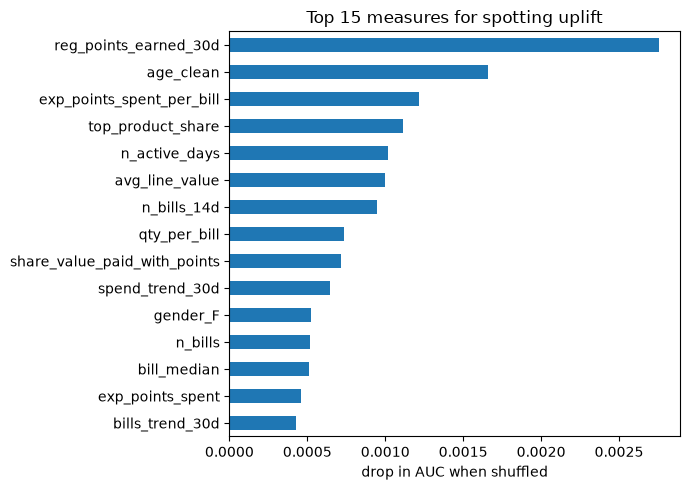

In [7]:
top = test[test[BEST] >= test[BEST].quantile(0.7)]; bot = test[test[BEST] <= test[BEST].quantile(0.3)]
key = ['recency_days', 'n_bills', 'bills_per_week', 'spend_total', 'bill_mean', 'spend_trend_30d', 'days_overdue_ratio',
       'lines_per_bill', 'n_stores', 'share_bills_reg_spent', 'share_bills_exp_spent', 'card_tenure_days',
       'ever_redeemed_by_cutoff', 'age_clean']
portrait = pd.DataFrame({'top 30% (persuadable)': top[key].median(), 'bottom 30%': bot[key].median()})
display(portrait.round(2))

sample = test.sample(min(20000, len(test)), random_state=42)
z_s = (sample.treatment_flg * sample.target + (1 - sample.treatment_flg) * (1 - sample.target)).astype(int)
t0 = time.time()
pi = permutation_importance(mZ, sample[X_COLS], z_s, scoring='roc_auc', n_repeats=3, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_COLS).sort_values(ascending=False)
print(f'importance computed in {time.time()-t0:.0f}s')
ax = imp.head(15)[::-1].plot.barh(figsize=(7, 5), title='Top 15 measures for spotting uplift'); ax.set_xlabel('drop in AUC when shuffled')
plt.tight_layout(); plt.show()

## Cell 7 · K4 verdict and save scores

In [8]:
r = res.loc[BEST]
dec_lift = dec.real_lift_pts.values
checks = {
    'Qini beats random (95% range above 0)': r.qini_low95 > 0,
    'Top 30% lift >= 1.5x average':          r.uplift_top30_pts >= 1.5 * r.avg_lift_pts,
    'Ranking holds (top 3 deciles > bottom 3)': dec_lift[:3].mean() > dec_lift[-3:].mean(),
}
for k, v in checks.items(): print(f'{"PASS" if v else "FAIL"}  {k}')
print('\nK4 VERDICT:', 'GO' if all(checks.values()) else 'STOP / REVIEW')

out = test[['client_id', 'treatment_flg', 'target', 'uplift_tlearner', 'uplift_classtrans']]
duckdb.register('out_df', out)
duckdb.sql(f"COPY out_df TO '{(FEAT / 'step3_test_scores.parquet').as_posix()}' (FORMAT PARQUET)")
print('saved step3_test_scores.parquet')

PASS  Qini beats random (95% range above 0)
PASS  Top 30% lift >= 1.5x average
PASS  Ranking holds (top 3 deciles > bottom 3)

K4 VERDICT: GO
saved step3_test_scores.parquet


## Your notes (2–3 lines in your own words)
- Did K4 pass? Which model won?
- What does a persuadable customer look like?
- If you could message only 30%, how much of the gain would you keep?